In [23]:
subject_folder = r"C:\Yoyi\Raw Data\3"

# Import Libraries

In [1]:
from BCI2kReader import BCI2kReader as b2k  # Library for reading BCI2000 files
import os                                   # Library to read file directories
import numpy as np                          # Library for array management
import pandas as pd                         # Library for managing data in tables
import matplotlib.pyplot as plt             # Library for plotting data
import math                                 # Library for mathematical operations and constants
import mne                                  # EEG/EMG processing library

import glob
import re

# 1 CONFIGURACIÓN GLOBAL

In [3]:
DATA_DIR = r"C:\Yoyi\Raw Data"
OUTPUT_DIR = r"C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud"
METADATA_FILE = os.path.join(DATA_DIR, "metadata.csv")

FS = 2400
TRIAL_SAMPLES = FS * 10
TRIALS_PER_RUN = 32
MIN_FILE_SIZE = 70000000  # 70 MB

ANALYZE_DURING = True

os.makedirs(OUTPUT_DIR, exist_ok=True)






# # fs = 512
# fs = 2400
# trialSamples = fs*10
# # normal_file_size = 14000000
# normal_file_size = 70000000
# trials_per_run = 32
# session = r"\001"

# # Obtain subject id to include in generated figures names
# # subject_id = subject_folder.split("sub-")[1].split("/")[0]
# subject_id = os.path.split(subject_folder)[1]

# output_dir = os.path.join(os.getcwd(), "output")

# 2 FUNCIONES DE EXTRACCIÓN Y MAPEO

In [4]:
def load_session_mapping(csv_path):
    """Devuelve mapeo { 'subject_id': { 'session_id': 'condition' } }"""
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Archivo de metadatos no encontrado: {csv_path}")
    #df = pd.read_csv(csv_path, dtype=str)
    #df = pd.read_csv(csv_path, dtype=str) 
    df = pd.read_csv(csv_path, dtype=str).dropna(subset=['subject_id'])
    mapping = {}
    for _, row in df.iterrows():
        if row['session_id'] == '1' or row['session_id'] == '2':
            row['session_id'] = '00' + row['session_id']
        sub, ses, cond = row['subject_id'], row['session_id'], row['condition']
        if sub not in mapping: mapping[sub] = {}
        mapping[sub][ses] = cond
    return mapping

def ConvertMotorEncoderToUIDisplacement(motor, RawData):
    """Mantenido de tu lógica original de conversión."""
    output = ((RawData * 25) / 65535) - 12.5
    if motor == "FE":
        output = output * 180 / math.pi
        for i in range(len(output)):
            output[i] = output[i] * 1.543 if output[i] >= 0 else output[i] * 1.559
    elif motor == "RUD":
        output = output * -180 / math.pi
        for i in range(len(output)):
            output[i] = output[i] * 4.866 if output[i] > 0 else output[i] * 2.3913
    else:
        return 0
    return output

def LoadingBCI2000Data(filename):
    """Carga cruda de BCI2000."""
    with b2k.BCI2kReader(filename) as test:
        my_signals, my_states = test.readall() 
    
    cols = test.parameters['ChannelNames']
    data = pd.DataFrame(my_signals.T, columns=cols)
    data['FE_Motor'] = my_states['XCoordinates'][0]
    data['RUD_Motor'] = my_states['YCoordinates'][0]
    data['TrialInit'] = my_states['TrialInitStamp'][0]
    data['AllTargetShow'] = my_states['AllTargetShowStamp'][0]
    data['InitMov'] = my_states['TrialInitMovStamp'][0] 
    data['InitReturnMov'] = my_states['TrialEndMovStamp'][0]
    data['CurrentTarget'] = my_states['CurrentTarget'][0] 

    init = data.loc[my_states['TrialInitStamp'][0] == 1].index[0]
    if init > TRIAL_SAMPLES:
        init = init - TRIAL_SAMPLES
    
    data = data.iloc[init:].reset_index(drop=True) #OJO REVISAR
    targets = np.zeros(shape=(TRIALS_PER_RUN), dtype=int)

    for x in range(TRIALS_PER_RUN):
        targets[x] = my_states['CurrentTarget'][0][x * TRIAL_SAMPLES + int(TRIAL_SAMPLES/2) + FS]
        data.loc[x * TRIAL_SAMPLES, 'CurrentTarget'] = targets[x]    

    data2D = np.zeros(shape=(23, TRIAL_SAMPLES * TRIALS_PER_RUN), dtype=np.float32)
    data2D[:,:] = data.iloc[0:TRIAL_SAMPLES * TRIALS_PER_RUN].transpose()
    data2D[16,:] = ConvertMotorEncoderToUIDisplacement(motor="FE", RawData=data2D[16,:])
    data2D[17,:] = ConvertMotorEncoderToUIDisplacement(motor="RUD", RawData=data2D[17,:])

    for i in range(0, 11):
        data2D[16,i] = data2D[16,10]
        data2D[17,i] = data2D[17,10]

    return data2D, cols, targets

def scan_and_categorize_runs(session_folder, subject_id, session_id):
    """Evasión de nomenclatura mediante tamaño y marca cronológica."""
    pattern = os.path.join(session_folder, f"{subject_id}S{session_id}R*.dat")
    all_files = glob.glob(pattern)
    regex = re.compile(r"R(\d{2})\(([\d\-]+)\)\.dat$")
    valid_files = []
    
    for filepath in all_files:
        if os.path.getsize(filepath) <= MIN_FILE_SIZE:
            continue
        match = regex.search(filepath)
        if match:
            valid_files.append((int(match.group(1)), match.group(2), filepath))
            
    valid_files.sort(key=lambda x: x[1]) # Orden estricto por timestamp
    
    blocks = {'pre': [], 'during': [], 'post': []}
    r02_files = [f for r, t, f in valid_files if r == 2]
    
    for r, t, filepath in valid_files:
        if r in [1, 11]: continue
        elif 3 <= r <= 6: blocks['pre'].append(filepath)
        elif 7 <= r <= 10: blocks['post'].append(filepath)
            
    if len(r02_files) > 1:
        blocks['during'] = r02_files #[1:5]

    return blocks

# 3 MOTOR DE PROCESAMIENTO

In [5]:
def run_extraction_pipeline(target_subject=None):
    """
    Ejecuta el pipeline.
    Si target_subject es None, procesa todas las carpetas en DATA_DIR que coincidan 
    con sujetos listados en el CSV de metadatos.
    """

    eeg_filters = (1.0, 60.0)
    emg_filters = (20.0, 1000.0)
    notch_emg_freqs = [180, 300, 420, 540, 660, 780, 900]
    eeg_reject_criteria = 150e-3  # Rechazo de artefactos EEG por amplitud
    #emg_reject_criteria = {"emg": 100e-6}

    session_map = load_session_mapping(METADATA_FILE)

    print(f"Filtros EEG: {eeg_filters[0]}-{eeg_filters[1]} Hz | EMG: {emg_filters[0]}-{emg_filters[1]} Hz + Notch {', '.join(map(str, notch_emg_freqs))} Hz")
    print(f"Rechazo de artefactos EEG:  Aplicado (umbral {eeg_reject_criteria*1e6:.0f} µV)")
    #print(f"Rechazo de artefactos EMG:  Aplicado (umbral {emg_reject_criteria * 1e6:.0f} µV)")
    
    if target_subject:
        if str(target_subject) not in session_map:
            raise ValueError(f"Sujeto {target_subject} no existe en metadata.csv")
        subjects_to_process = [str(target_subject)]
    else:
        # Detectar sujetos disponibles en el directorio raíz basándose en el CSV
        subjects_to_process = [s for s in session_map.keys() if os.path.isdir(os.path.join(DATA_DIR, s))]

    print(f"\nIniciando extracción para {len(subjects_to_process)} sujeto(s): {subjects_to_process}")

    for subject in subjects_to_process:
        print(f"\n[{subject}] Procesando...")
        
        for session_id, condition in session_map[subject].items():
            print(f"  [{session_id} -> {condition.upper()}]")
            session_folder = os.path.join(DATA_DIR, subject, session_id)
            if not os.path.exists(session_folder):
                print(f"    [!] Directorio no encontrado: {session_folder}")
                continue

            dynamic_blocks = scan_and_categorize_runs(session_folder, subject, session_id)
            
            for block_name, filepaths in dynamic_blocks.items():
                if not filepaths or (block_name == 'during' and not ANALYZE_DURING):
                    continue
                
                # Archivos de salida esperados
                base_out = os.path.join(OUTPUT_DIR, f"sub-{subject}_cond-{condition}_blk-{block_name}")
                if os.path.exists(f"{base_out}_eeg-epo.fif"):
                    print(f"    -> Bloque '{block_name}' ya procesado. Omitiendo.")
                    continue
                
                epochsEEG_list, epochsEMG_list, epochsKin_list = [], [], []
                
                for filename in filepaths:
                    data2D, cols, targets = LoadingBCI2000Data(filename)
                    events = np.column_stack((
                        np.linspace(0, targets.size - 1, targets.size, dtype=int) * TRIAL_SAMPLES,
                        np.zeros(targets.size, dtype=int),
                        targets
                    ))

                    # Estructuración MNE 
                    # EEG
                    info_eeg = mne.create_info(ch_names=cols[0:8], sfreq=FS, ch_types=['eeg']*8, verbose=False)
                    
                    raw_eeg = mne.io.RawArray(data2D[0:8, :] * 1e-6, info_eeg, verbose=False)

                    raw_eeg.filter(l_freq=eeg_filters[0], h_freq=eeg_filters[1], picks='all', verbose=False)

                    montage = mne.channels.make_standard_montage('standard_1020')
                    raw_eeg.set_montage(montage, verbose=False) # Se aplica a raw_eeg

                    #quitar luego
                    #raw_eeg.plot(n_channels=8, scalings='auto', title=f"EEG - {subject} {condition} {block_name}")

                    # epochsEEG_list.append(mne.Epochs(raw_eeg, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True))

                    if(block_name == 'during' and ANALYZE_DURING):
                        epochsEEG_list.append(mne.Epochs(raw_eeg, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True))
                    else:
                        epochsEEG_list.append(mne.Epochs(raw_eeg, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True, reject = {"eeg": eeg_reject_criteria}))
                    
                    # EMG 
                    info_emg = mne.create_info(ch_names=cols[8:16], sfreq=FS, ch_types=['emg']*8, verbose=False)
                    raw_emg = mne.io.RawArray(data2D[8:16, :] * 1e-6, info_emg, verbose=False)
                    raw_emg.filter(l_freq=emg_filters[0], h_freq=emg_filters[1], picks='all', verbose=False)
                    raw_emg.notch_filter(freqs=notch_emg_freqs, picks='all', verbose=False)
                    epochsEMG_list.append(mne.Epochs(raw_emg, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True))
                    
                    # Cinemática
                    info_kin = mne.create_info(ch_names=['FES_Motor', 'RUD_Motor'], sfreq=FS, ch_types=['misc']*2, verbose=False)
                    raw_kin = mne.io.RawArray(data2D[16:18, :], info_kin, verbose=False)
                    raw_kin.filter(l_freq=None, h_freq=250.0, picks='all', verbose=False)
                    epochsKin_list.append(mne.Epochs(raw_kin, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True))
                
                # Concatenar y guardar
                # Se queda únicamente con los objetos Epochs que tienen más de 0 épocas
                epochsEEG_validos = [ep for ep in epochsEEG_list if len(ep) > 0]

                if epochsEEG_validos:
                    eeg_epochs = mne.concatenate_epochs(epochsEEG_validos, verbose=False)
                    #Quitar luego
                    eeg_epochs.plot(n_channels=8, scalings='auto', title=f"EEG - {subject} {condition} {block_name}", show=False)

                    eeg_epochs.save(f"{base_out}_eeg-epo.fif", overwrite=True)
                    #mne.concatenate_epochs(epochsEEG_list, verbose=False).save(f"{base_out}_eeg-epo.fif", overwrite=True)
                    mne.concatenate_epochs(epochsEMG_list, verbose=False).save(f"{base_out}_emg-epo.fif", overwrite=True)
                    mne.concatenate_epochs(epochsKin_list, verbose=False).save(f"{base_out}_kin-epo.fif", overwrite=True)
                    print(f"    -> Exportado: {base_out}")
                    print(f"Tamaño de datos EEG luego de rechazo por amplitud: {len(eeg_epochs)}\n")

    print("\nEjecución finalizada con éxito.")

# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == '__main__':
    # Para procesar un sujeto específico:
    # run_extraction_pipeline(target_subject="10")
    
    # Para procesar toda la base de datos de un golpe:
    run_extraction_pipeline()

Filtros EEG: 1.0-60.0 Hz | EMG: 20.0-1000.0 Hz + Notch 180, 300, 420, 540, 660, 780, 900 Hz
Rechazo de artefactos EEG:  Aplicado (umbral 150000 µV)

Iniciando extracción para 19 sujeto(s): ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19']

[1] Procesando...
  [001 -> SHAM]
  [002 -> STIM]

[2] Procesando...
  [001 -> STIM]
  [002 -> SHAM]

[3] Procesando...
  [001 -> STIM]
    -> Bloque 'pre' ya procesado. Omitiendo.
    -> Bloque 'during' ya procesado. Omitiendo.
    -> Bloque 'post' ya procesado. Omitiendo.

[4] Procesando...
  [001 -> STIM]
    -> Bloque 'pre' ya procesado. Omitiendo.
    -> Bloque 'during' ya procesado. Omitiendo.
    -> Bloque 'post' ya procesado. Omitiendo.

[5] Procesando...
  [001 -> STIM]
    -> Bloque 'pre' ya procesado. Omitiendo.
    -> Bloque 'during' ya procesado. Omitiendo.
    -> Bloque 'post' ya procesado. Omitiendo.
  [002 -> SHAM]
    -> Bloque 'pre' ya procesado. Omitiendo.
    -> Bloque 'durin

Using qt as 2D backend.


    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-12_cond-stim_blk-during
Tamaño de datos EEG luego de rechazo por amplitud: 128



    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-12_cond-stim_blk-post
Tamaño de datos EEG luego de rechazo por amplitud: 128


[13] Procesando...
  [001 -> SHAM]


    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-13_cond-sham_blk-pre
Tamaño de datos EEG luego de rechazo por amplitud: 128



    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-13_cond-sham_blk-during
Tamaño de datos EEG luego de rechazo por amplitud: 128



... (27 outputs left out)

    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-18_cond-sham_blk-post
Tamaño de datos EEG luego de rechazo por amplitud: 128


[19] Procesando...
  [001 -> STIM]


    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-19_cond-stim_blk-pre
Tamaño de datos EEG luego de rechazo por amplitud: 128



    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-19_cond-stim_blk-during
Tamaño de datos EEG luego de rechazo por amplitud: 128



    -> Exportado: C:\Yoyi\Preprocessed Data\Sin rechazo por amplitud\sub-19_cond-stim_blk-post
Tamaño de datos EEG luego de rechazo por amplitud: 128


Ejecución finalizada con éxito.


# Temp

Iniciando análisis para Sujeto 10 | Condición: STIM
Aplicando filtros espectrales...
Calculando Densidad Espectral de Potencia (PSD)...
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


C:\Users\jorge\AppData\Local\Temp\ipykernel_32376\2106347856.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


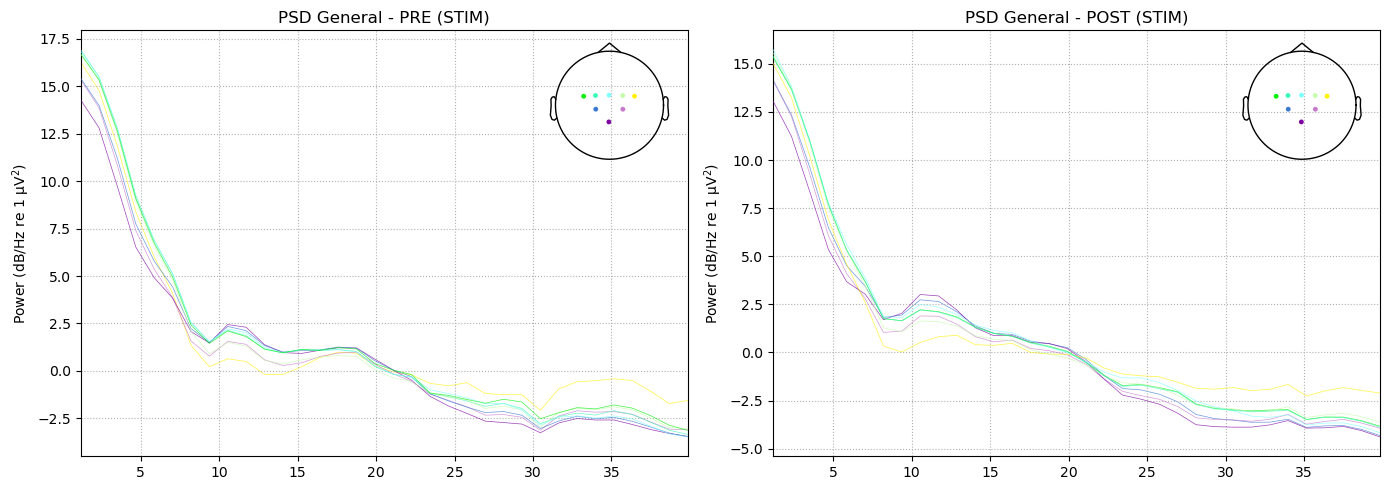

In [ ]:
import os
import mne
import matplotlib.pyplot as plt

# ==============================================================================
# 1. PARÁMETROS DE CARGA
# ==============================================================================
processed_dir = OUTPUT_DIR # Ajusta a tu ruta real
subject = "10"
condition = "stim"

print(f"Iniciando análisis para Sujeto {subject} | Condición: {condition.upper()}")

# ==============================================================================
# 2. CARGA DE DATOS (MNE Native)
# ==============================================================================
# Definición de rutas
file_pre = os.path.join(processed_dir, f"sub-{subject}_cond-{condition}_blk-pre_eeg-epo.fif")
file_post = os.path.join(processed_dir, f"sub-{subject}_cond-{condition}_blk-post_eeg-epo.fif")

# Carga de las épocas en memoria (extremadamente rápido)
epochs_pre = mne.read_epochs(file_pre, preload=True, verbose=False)
epochs_post = mne.read_epochs(file_post, preload=True, verbose=False)

# ==============================================================================
# 3. PREPROCESAMIENTO ESPECÍFICO PARA EL BIOMARCADOR
# ==============================================================================
# Utilizamos .copy() para no alterar las variables originales en RAM
# Filtro enfocado en la banda Mu/Alpha (8 - 12 Hz) clásica en tareas motoras
print("Aplicando filtros espectrales...")
epochs_pre_mu = epochs_pre.copy().filter(l_freq=8.0, h_freq=35.0, verbose=False)
epochs_post_mu = epochs_post.copy().filter(l_freq=8.0, h_freq=35.0, verbose=False)

# ==============================================================================
# 4. EXTRACCIÓN DE MÉTRICAS (Ejemplo: PSD de Welch)
# ==============================================================================
print("Calculando Densidad Espectral de Potencia (PSD)...")
# Limitamos la visualización a las frecuencias de interés general (1-40 Hz)
psd_pre = epochs_pre.compute_psd(fmin=1.0, fmax=40.0, method='welch', verbose=False)
psd_post = epochs_post.compute_psd(fmin=1.0, fmax=40.0, method='welch', verbose=False)

# ==============================================================================
# 5. VISUALIZACIÓN DE PRUEBA
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Promedio de canales Pre-Stim
psd_pre.plot(axes=axes[0], show=False)
axes[0].set_title(f'PSD General - PRE ({condition.upper()})')

# Plot Promedio de canales Post-Stim
psd_post.plot(axes=axes[1], show=False)
axes[1].set_title(f'PSD General - POST ({condition.upper()})')

plt.tight_layout()
plt.show()

# Testing

In [ ]:
#print(load_session_mapping(METADATA_FILE))
print(scan_and_categorize_runs(DATA_DIR+r"\3\001", "3", "001"))

{'pre': ['C:\\Yoyi\\Raw Data\\3\\001\\3S001R03(2026-03-10-11-12-35).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R04(2026-03-10-11-18-56).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R05(2026-03-10-11-25-47).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R06(2026-03-10-11-32-22).dat'], 'during': ['C:\\Yoyi\\Raw Data\\3\\001\\3S001R02(2026-03-10-11-43-41).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R02(2026-03-10-11-57-19).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R02(2026-03-10-12-05-02).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R02(2026-03-10-12-11-33).dat'], 'post': ['C:\\Yoyi\\Raw Data\\3\\001\\3S001R07(2026-03-10-12-18-57).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R08(2026-03-10-12-25-55).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R09(2026-03-10-12-32-57).dat', 'C:\\Yoyi\\Raw Data\\3\\001\\3S001R10(2026-03-10-12-39-09).dat']}
